# Data quality of the hotel bookings dataset

**Data source:** Antonio, N., de Almeida, A. and Nunes, L. (2019). *Hotel booking demand datasets*. Data in Brief, 22, 41–49. https://doi.org/10.1016/j.dib.2018.11.126 (file `hotel_bookings_dataset.csv`).
**Date:** 2026-11-04
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** This notebook measures the quality problems of the raw data (Part 1, task 1.2): missing values and placeholders, duplicated rows, impossible or odd values, incoherent dates, and the overlap between `is_canceled` and `reservation_status`. It changes nothing: the numbers are the evidence for the cleaning rules that the students will choose in task 1.6.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
   - 2.1 Missing values and placeholders
   - 2.2 Duplicated rows
   - 2.3 Impossible or odd values
   - 2.4 Coherence of the dates
   - 2.5 `is_canceled` and `reservation_status`
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: summary of the issues](#4.-Analysis:-summary-of-the-issues)
5. [Accessible visualisation](#5.-Accessible-visualisation)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Paths: the raw file is read-only; results go to this notebook's output folder,
# and the figure used in the Part 1 text goes to the part's images folder
RAW_FILE   = Path('../../Course information/hotel_bookings_dataset.csv')
OUTPUT_DIR = Path('data_quality_output')
IMAGES_DIR = Path('../images')
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

print('pandas', pd.__version__, '| matplotlib', matplotlib.__version__)
print('Raw file found:', RAW_FILE.exists())

pandas 2.3.3 | matplotlib 3.10.9
Raw file found: True


## 1. Data loading

In [2]:
# ── Load ──────────────────────────────────────────────────────────────────────

# Copy 1, as text: every value exactly as written in the file (placeholders included)
raw_text = pd.read_csv(RAW_FILE, dtype=str, keep_default_na=False)

# Copy 2, typed: only the two placeholders NA and NULL become missing (NaN), so the
# numeric columns get numeric types; 'Undefined' stays as a category
bookings = pd.read_csv(RAW_FILE, keep_default_na=False, na_values=['NA', 'NULL'])

TOTAL_ROWS = len(bookings)
print(f'Rows: {TOTAL_ROWS:,} | Columns: {bookings.shape[1]}')
bookings.dtypes.value_counts()

Rows: 119,390 | Columns: 32


int64      16
object     12
float64     4
Name: count, dtype: int64

### Decision: two copies of the same file

**Context:** to count placeholders we need the text exactly as written; to check values (for example a negative price) we need numbers.

**Decision taken:** `raw_text` keeps every value as text, and `bookings` turns only `NA` and `NULL` into missing values, so `children`, `agent` and `company` become numeric. Neither copy is changed afterwards.

**Alternatives considered:** pandas' default reading turns more strings into NaN (for example `N/A` or `nan`) without telling us; listing the two placeholders explicitly keeps control of what is treated as missing.

## 2. Initial exploration

### 2.1 Missing values and placeholders

In [3]:
# ── Placeholders per field ───────────────────────────────────────────────────

placeholder_counts = pd.DataFrame({
    'empty':     (raw_text == '').sum(),
    'NA':        (raw_text == 'NA').sum(),
    'NULL':      (raw_text == 'NULL').sum(),
    'Undefined': (raw_text == 'Undefined').sum(),
})
placeholder_counts['total'] = placeholder_counts.sum(axis=1)
placeholder_counts['% of rows'] = (100 * placeholder_counts['total'] / TOTAL_ROWS).round(2)

placeholder_counts = placeholder_counts[placeholder_counts['total'] > 0].sort_values('total', ascending=False)
placeholder_counts

,empty,NA,NULL,Undefined,total,% of rows
company,0,0,112593,0,112593,94.31
agent,0,0,16340,0,16340,13.69
meal,0,0,0,1169,1169,0.98
country,0,0,488,0,488,0.41
distribution_channel,0,0,0,5,5,0.00
children,0,4,0,0,4,0.00
market_segment,0,0,0,2,2,0.00


In [4]:
# ── What does NULL mean in agent and company? ────────────────────────────────

# The paper says NULL = "not applicable". If that is true, bookings without an agent
# should come mostly from channels that do not use agencies (Direct, Corporate)
agent_by_channel = pd.crosstab(bookings['agent'].isna().map({True: 'agent NULL', False: 'agent given'}),
                               bookings['distribution_channel'])
agent_by_channel

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
agent,,,,,
agent NULL,5543,7625,2,3167,3
agent given,1134,7020,191,94703,2


In [5]:
# Share of bookings with a company, by market segment
company_by_segment = (bookings.groupby('market_segment')['company']
                      .apply(lambda ids: 100 * ids.notna().mean())
                      .round(1)
                      .sort_values(ascending=False)
                      .rename('% of bookings with a company'))
company_by_segment

market_segment
Aviation         89.5
Corporate        84.4
Complementary    42.1
Groups            7.0
Direct            1.7
Offline TA/TO     0.4
Online TA         0.2
Undefined         0.0
Name: % of bookings with a company, dtype: float64

In [6]:
# ── country NULL, children NA and the Undefined categories ───────────────────

# Where are the bookings without a country?
print('country NULL by hotel:')
print(bookings.loc[bookings['country'].isna(), 'hotel'].value_counts().to_string())

# The four rows with children = NA, and the rows with Undefined segment or channel
undefined_rows = bookings[bookings['children'].isna()
                          | (bookings['market_segment'] == 'Undefined')
                          | (bookings['distribution_channel'] == 'Undefined')]
undefined_rows[['hotel', 'children', 'market_segment', 'distribution_channel', 'country', 'adr', 'is_canceled']]

country NULL by hotel:
hotel
Resort Hotel    464
City Hotel       24


,hotel,children,market_segment,distribution_channel,country,adr,is_canceled
14594,Resort Hotel,1.0,Direct,Undefined,PRT,112.7,0
40600,City Hotel,NaN,Undefined,Undefined,PRT,12.0,1
40667,City Hotel,NaN,Direct,Undefined,PRT,12.0,1
40679,City Hotel,NaN,Undefined,Undefined,PRT,18.0,1
41160,City Hotel,NaN,Online TA,Undefined,PRT,76.5,1


In [7]:
# ── meal: Undefined versus SC ────────────────────────────────────────────────

# The paper groups "Undefined/SC" as "no meal package". Do both hotels use both codes?
meal_by_hotel = pd.crosstab(bookings['meal'], bookings['hotel'])
meal_by_hotel

hotel,City Hotel,Resort Hotel
meal,,
BB,62305,30005
FB,44,754
HB,6417,8046
SC,10564,86
Undefined,0,1169


### Findings on placeholders

- `company` (`NULL` in 94.3 % of the rows) and `agent` (13.7 %) are **"not applicable"**, as the paper says, not gaps: bookings without an agent are concentrated in the Direct and Corporate channels, and companies appear mainly in the Corporate, Aviation and Complementary segments.
- `country` has 488 `NULL` (0.4 %), almost all in the Resort Hotel. Every guest has a country, so these are **real gaps**.
- `children` has 4 `NA`. These four rows are also four of the five rows with `distribution_channel = Undefined`, and two of them have `market_segment = Undefined`: a small group of badly recorded bookings in the City Hotel.
- `meal = Undefined` (1,169) appears **only in the Resort Hotel**, while `SC` is almost only used by the City Hotel. Together with the paper's "Undefined/SC = no meal package", this suggests the two hotels used different codes for the same thing.

### 2.2 Duplicated rows

In [8]:
# ── Fully duplicated rows ────────────────────────────────────────────────────

# A row is a duplicate when all 32 values are equal to an earlier row
is_duplicate = raw_text.duplicated(keep='first')
in_duplicate_group = raw_text.duplicated(keep=False)

n_duplicates = int(is_duplicate.sum())
print(f'Rows that repeat an earlier row: {n_duplicates:,} ({100 * n_duplicates / TOTAL_ROWS:.1f} % of all rows)')
print(f'Rows that belong to a group of identical rows: {int(in_duplicate_group.sum()):,}')
print(f'Rows left if each group kept one copy: {TOTAL_ROWS - n_duplicates:,}')

Rows that repeat an earlier row: 31,994 (26.8 % of all rows)
Rows that belong to a group of identical rows: 40,165
Rows left if each group kept one copy: 87,396


In [9]:
# How big are the groups of identical rows?
group_sizes = raw_text.groupby(list(raw_text.columns)).size()
group_size_counts = group_sizes[group_sizes > 1].value_counts().sort_index()
print('Largest group of identical rows:', group_sizes.max())
group_size_counts.head(10).rename_axis('copies in the group').rename('number of groups')

Largest group of identical rows: 180


copies in the group
2     5034
3      969
4      497
5      275
6      171
7      115
8      103
9       93
10     123
11      60
Name: number of groups, dtype: int64

In [10]:
# ── Where are the duplicates? ────────────────────────────────────────────────

# Percentage of duplicated rows inside each group of bookings
def duplicate_share(field):
    return (100 * is_duplicate.groupby(bookings[field]).mean()).round(1).rename('% duplicated')

duplicates_by = pd.concat({
    'hotel':        duplicate_share('hotel'),
    'is_canceled':  duplicate_share('is_canceled'),
    'deposit_type': duplicate_share('deposit_type'),
    'customer_type': duplicate_share('customer_type'),
})
duplicates_by

hotel          City Hotel         32.7
               Resort Hotel       15.2
is_canceled    0                  15.7
               1                  45.7
deposit_type   No Deposit         17.6
               Non Refund         92.9
               Refundable         34.0
customer_type  Contract           23.0
               Group               5.7
               Transient          19.7
               Transient-Party    53.3
Name: % duplicated, dtype: float64

### Finding: the duplicates are probably not all errors

**Context:** about a quarter of the rows repeat an earlier row in all 32 fields. The dataset has **no booking identifier**, so we cannot know whether two identical rows are the same booking recorded twice or two different bookings that happen to look the same (for example several rooms of one group, booked on the same day by the same tour operator).

**What the data shows:** the duplicates are concentrated in the City Hotel, in cancelled bookings, in `Transient-Party` bookings and above all in `Non Refund` deposits. This looks more like blocks of rooms booked together (for example by a tour operator) than like random copying errors, but it is only a hypothesis: the `Group` customer type, for example, has few duplicates.

> ⚠️ **Limitation:** removing them would lower the cancellation rate and the City Hotel's share; keeping them may count some bookings twice. The choice is left to the students in task 1.6.

### 2.3 Impossible or odd values

In [11]:
# ── Helper columns used only for the checks ─────────────────────────────────

total_nights = bookings['stays_in_weekend_nights'] + bookings['stays_in_week_nights']
total_guests = bookings['adults'] + bookings['children'].fillna(0) + bookings['babies']

print('Nights per booking:', total_nights.min(), 'to', total_nights.max())
print('Guests per booking:', total_guests.min(), 'to', total_guests.max())

Nights per booking: 0 to 69
Guests per booking: 0.0 to 55.0


In [12]:
# ── Average daily rate (adr) ─────────────────────────────────────────────────

print('adr below 0:', (bookings['adr'] < 0).sum())
print(bookings.loc[bookings['adr'] < 0, ['hotel', 'adr', 'market_segment', 'is_canceled']].to_string())
print()
print('adr equal to 0:', (bookings['adr'] == 0).sum())
print('  of which Complementary segment:', ((bookings['adr'] == 0) & (bookings['market_segment'] == 'Complementary')).sum())
print('  of which 0 nights:', ((bookings['adr'] == 0) & (total_nights == 0)).sum())
print('  of which Complementary or 0 nights (either):',
      ((bookings['adr'] == 0) & ((bookings['market_segment'] == 'Complementary') | (total_nights == 0))).sum())
print()
print('Five highest adr values:', bookings['adr'].nlargest(5).tolist())
bookings.loc[[bookings['adr'].idxmax()], ['hotel', 'adr', 'adults', 'stays_in_week_nights', 'market_segment', 'is_canceled']]

adr below 0: 1
              hotel   adr market_segment  is_canceled
14969  Resort Hotel -6.38         Groups            0

adr equal to 0: 1959
  of which Complementary segment: 680
  of which 0 nights: 715
  of which Complementary or 0 nights (either): 1372

Five highest adr values: [5400.0, 510.0, 508.0, 451.5, 450.0]


,hotel,adr,adults,stays_in_week_nights,market_segment,is_canceled
48515,City Hotel,5400.0,2,1,Offline TA/TO,1


In [13]:
# ── Guests ────────────────────────────────────────────────────────────────────

print('Bookings with 0 adults:', (bookings['adults'] == 0).sum())
print('  of which with children or babies:', ((bookings['adults'] == 0) & (total_guests > 0)).sum())
print('Bookings with 0 guests in total:', (total_guests == 0).sum())
print()
print('Bookings with more than 4 adults:', (bookings['adults'] > 4).sum())
print('  adult values above 4:', bookings.loc[bookings['adults'] > 4, 'adults'].value_counts().sort_index().to_dict())
print('children values:', bookings['children'].value_counts().sort_index().to_dict())
print('babies values:', bookings['babies'].value_counts().sort_index().to_dict())
print('parking spaces values:', bookings['required_car_parking_spaces'].value_counts().sort_index().to_dict())

Bookings with 0 adults: 403
  of which with children or babies: 223
Bookings with 0 guests in total: 180

Bookings with more than 4 adults: 16
  adult values above 4: {5: 2, 6: 1, 10: 1, 20: 2, 26: 5, 27: 2, 40: 1, 50: 1, 55: 1}
children values: {0.0: 110796, 1.0: 4861, 2.0: 3652, 3.0: 76, 10.0: 1}
babies values: {0: 118473, 1: 900, 2: 15, 9: 1, 10: 1}
parking spaces values: {0: 111974, 1: 7383, 2: 28, 3: 3, 8: 2}


In [14]:
# ── Stays of 0 nights ────────────────────────────────────────────────────────

zero_nights = total_nights == 0
print('Bookings with 0 nights:', zero_nights.sum())
bookings.loc[zero_nights, 'reservation_status'].value_counts()

Bookings with 0 nights: 715


reservation_status
Check-Out    680
Canceled      22
No-Show       13
Name: count, dtype: int64

In [15]:
# ── Country codes ────────────────────────────────────────────────────────────

# 'CN' is a two-letter code; China's three-letter code 'CHN' is also present
country_check = pd.crosstab(bookings.loc[bookings['country'].isin(['CN', 'CHN']), 'country'],
                            bookings['hotel'])
country_check

hotel,City Hotel,Resort Hotel
country,,
CHN,865,134
CN,569,710


### Findings on values

- One booking has a **negative** `adr` (−6.38), which is impossible for a price; one has `adr` = **5,400**, ten times the next highest value (510), for a cancelled one-night booking of two adults: probably a typing error.
- `adr` = 0 in 1,959 bookings. It is plausible for the Complementary segment (free stays) and for 0-night bookings (1,372 of them are one or the other), but not obviously for the rest.
- 403 bookings have **0 adults**; 180 of them have **no guests at all**, which is impossible for a real stay.
- 715 bookings have **0 nights**; most of them were checked out, so they may be day-use bookings.
- Large values such as 55 adults, 10 children, 9–10 babies or 8 parking spaces are rare (a handful of rows each); big adult numbers may be groups, but 9–10 babies is very unlikely.
- `CN` and `CHN` both appear, with different hotel patterns; `CN` is probably China written with the two-letter code, but the source does not say so.

### 2.4 Coherence of the dates

In [16]:
# ── Arrival date ─────────────────────────────────────────────────────────────

# Build a real date from the three arrival fields; errors='coerce' would show impossible dates as NaT
month_number = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
                'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}
arrival_date = pd.to_datetime(pd.DataFrame({'year':  bookings['arrival_date_year'],
                                            'month': bookings['arrival_date_month'].map(month_number),
                                            'day':   bookings['arrival_date_day_of_month']}),
                              errors='coerce')

print('Impossible arrival dates:', arrival_date.isna().sum())
print('First arrival:', arrival_date.min().date(), '| last arrival:', arrival_date.max().date())

Impossible arrival dates: 0
First arrival: 2015-07-01 | last arrival: 2017-08-31


In [17]:
# ── Week number ──────────────────────────────────────────────────────────────

# Compare with the ISO week (weeks start on Monday)
iso_week = arrival_date.dt.isocalendar().week.astype(int)
print('Rows where the week number equals the ISO week:', (iso_week == bookings['arrival_date_week_number']).sum())

# Test another rule: weeks start on Sunday and week 1 is the week that contains 1 January
first_of_january = pd.to_datetime(pd.DataFrame({'year': bookings['arrival_date_year'], 'month': 1, 'day': 1}))
days_since_sunday = (first_of_january.dt.dayofweek + 1) % 7
sunday_week = (arrival_date.dt.dayofyear - 1 + days_since_sunday) // 7 + 1
print('Rows where the week number follows the Sunday rule:', (sunday_week == bookings['arrival_date_week_number']).sum(),
      'of', TOTAL_ROWS)

Rows where the week number equals the ISO week: 55336
Rows where the week number follows the Sunday rule: 119390 of 119390


In [18]:
# ── Reservation status date versus arrival date ──────────────────────────────

status_date = pd.to_datetime(bookings['reservation_status_date'])
departure_date = arrival_date + pd.to_timedelta(total_nights, unit='D')
status = bookings['reservation_status']

date_checks = pd.Series({
    'Check-Out: status date = arrival + nights':  ((status == 'Check-Out') & (status_date == departure_date)).sum(),
    'Check-Out: status date different':           ((status == 'Check-Out') & (status_date != departure_date)).sum(),
    'Canceled: status date on or before arrival': ((status == 'Canceled') & (status_date <= arrival_date)).sum(),
    'Canceled: status date after arrival':        ((status == 'Canceled') & (status_date > arrival_date)).sum(),
    'No-Show: status date = arrival':             ((status == 'No-Show') & (status_date == arrival_date)).sum(),
    'No-Show: status date different':             ((status == 'No-Show') & (status_date != arrival_date)).sum(),
    'Status date before the first arrival (2015-07-01)': (status_date < arrival_date.min()).sum(),
}, name='bookings')
date_checks

Check-Out: status date = arrival + nights            75139
Check-Out: status date different                        27
Canceled: status date on or before arrival           43017
Canceled: status date after arrival                      0
No-Show: status date = arrival                        1206
No-Show: status date different                           1
Status date before the first arrival (2015-07-01)     2350
Name: bookings, dtype: int64

In [19]:
# Status of the bookings whose status date is before the first arrival
status[status_date < arrival_date.min()].value_counts()

reservation_status
Canceled    2350
Name: count, dtype: int64

### Findings on dates

- All arrival dates are real calendar dates, from 2015-07-01 to 2017-08-31.
- `arrival_date_week_number` is **not** the ISO week: it follows, in every row, a rule where weeks start on Sunday and week 1 is the week of 1 January. It is coherent, but it must not be mixed with ISO weeks.
- `reservation_status_date` is coherent with the status: for check-outs it is the departure day (all but 27 rows), for cancellations it is on or before the arrival, for no-shows it is the arrival day (all but one). The dates before July 2015 are all **cancellations made in advance**, so they are not errors: the status date is when the booking was cancelled, not when the guest arrived.

### 2.5 `is_canceled` and `reservation_status`

In [20]:
# ── Overlap between the two fields ───────────────────────────────────────────
status_by_canceled = pd.crosstab(bookings['reservation_status'], bookings['is_canceled'], margins=True)
status_by_canceled

is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


### Finding: `reservation_status` contains `is_canceled`

Every `Canceled` and `No-Show` booking has `is_canceled` = 1, and every `Check-Out` has `is_canceled` = 0. So `reservation_status` is `is_canceled` split into a little more detail (it separates no-shows from cancellations). Using it to "explain" cancellations would be **circular**: it is the same fact, recorded afterwards. In the dashboard it can only be used to *describe* cancellations (for example cancellations versus no-shows), never as a cause.

## 3. Cleaning and preparation

Nothing is cleaned here. This notebook only measures the problems. The students choose a rule for each one in task 1.6, and only `clean_hotel_bookings.py` applies those rules.

## 4. Analysis: summary of the issues

In [21]:
# ── One row per issue, with the number of bookings affected ──────────────────

# kind: placeholder, duplicate, odd value, incoherence or redundancy
# needs_rule: whether task 1.6 must decide what to do with it
issues = [
    dict(issue='Row identical to an earlier row', fields='all fields', kind='duplicate',
         rows=n_duplicates, needs_rule='Yes'),
    dict(issue='company = NULL (no company)', fields='company', kind='placeholder',
         rows=(raw_text['company'] == 'NULL').sum(), needs_rule='Yes'),
    dict(issue='agent = NULL (no agency)', fields='agent', kind='placeholder',
         rows=(raw_text['agent'] == 'NULL').sum(), needs_rule='Yes'),
    dict(issue='adr = 0', fields='adr', kind='odd value',
         rows=(bookings['adr'] == 0).sum(), needs_rule='Yes'),
    dict(issue='meal = Undefined (= SC?)', fields='meal', kind='placeholder',
         rows=(raw_text['meal'] == 'Undefined').sum(), needs_rule='Yes'),
    dict(issue='country = CN (CHN also used)', fields='country', kind='incoherence',
         rows=(raw_text['country'] == 'CN').sum(), needs_rule='Yes'),
    dict(issue='0 nights', fields='stays_in_weekend_nights, stays_in_week_nights', kind='odd value',
         rows=zero_nights.sum(), needs_rule='Yes'),
    dict(issue='country = NULL (real gap)', fields='country', kind='placeholder',
         rows=(raw_text['country'] == 'NULL').sum(), needs_rule='Yes'),
    dict(issue='0 adults', fields='adults', kind='odd value',
         rows=(bookings['adults'] == 0).sum(), needs_rule='Yes'),
    dict(issue='0 guests in total', fields='adults, children, babies', kind='odd value',
         rows=(total_guests == 0).sum(), needs_rule='Yes'),
    dict(issue='Check-Out status date is not arrival + nights', fields='reservation_status_date', kind='incoherence',
         rows=date_checks['Check-Out: status date different'], needs_rule='Yes'),
    dict(issue='distribution_channel = Undefined', fields='distribution_channel', kind='placeholder',
         rows=(raw_text['distribution_channel'] == 'Undefined').sum(), needs_rule='Yes'),
    dict(issue='children = NA', fields='children', kind='placeholder',
         rows=(raw_text['children'] == 'NA').sum(), needs_rule='Yes'),
    dict(issue='market_segment = Undefined', fields='market_segment', kind='placeholder',
         rows=(raw_text['market_segment'] == 'Undefined').sum(), needs_rule='Yes'),
    dict(issue='babies = 9 or 10', fields='babies', kind='odd value',
         rows=(bookings['babies'] >= 9).sum(), needs_rule='Yes'),
    dict(issue='adr below 0', fields='adr', kind='odd value',
         rows=(bookings['adr'] < 0).sum(), needs_rule='Yes'),
    dict(issue='adr = 5,400 (next highest: 510)', fields='adr', kind='odd value',
         rows=(bookings['adr'] == 5400).sum(), needs_rule='Yes'),
    dict(issue='Week number is not the ISO week (coherent Sunday rule)', fields='arrival_date_week_number',
         kind='incoherence', rows=(iso_week != bookings['arrival_date_week_number']).sum(), needs_rule='No, only document'),
    dict(issue='Status date before the first arrival (early cancellations)', fields='reservation_status_date',
         kind='incoherence', rows=date_checks['Status date before the first arrival (2015-07-01)'], needs_rule='No, it is correct'),
    dict(issue='reservation_status repeats is_canceled', fields='reservation_status, is_canceled',
         kind='redundancy', rows=TOTAL_ROWS, needs_rule='No, but never use it to explain cancellations'),
]

issues_summary = pd.DataFrame(issues)
issues_summary['rows'] = issues_summary['rows'].astype(int)
issues_summary['% of rows'] = (100 * issues_summary['rows'] / TOTAL_ROWS).round(2)
issues_summary

,issue,fields,kind,rows,needs_rule,% of rows
0,Row identical to an earlier row,all fields,duplicate,31994,Yes,26.80
1,company = NULL (no company),company,placeholder,112593,Yes,94.31
2,agent = NULL (no agency),agent,placeholder,16340,Yes,13.69
3,adr = 0,adr,odd value,1959,Yes,1.64
4,meal = Undefined (= SC?),meal,placeholder,1169,Yes,0.98
5,country = CN (CHN also used),country,incoherence,1279,Yes,1.07
6,0 nights,"stays_in_weekend_nights, stays_in_week_nights",odd value,715,Yes,0.60
7,country = NULL (real gap),country,placeholder,488,Yes,0.41
8,0 adults,adults,odd value,403,Yes,0.34
9,0 guests in total,"adults, children, babies",odd value,180,Yes,0.15


## 5. Accessible visualisation

One chart summarises how many bookings each issue affects, so the reader can judge which problems matter. A **horizontal bar chart** is used because the issue names are long and the task is to compare magnitudes (Visual Vocabulary, "magnitude"; length is read accurately, Cleveland & McGill). Bars are sorted by size, start at zero and carry their exact value as a label, so colour carries no information and a single dark blue is enough (contrast above 3:1 for graphics, WCAG 1.4.11). A logarithmic axis was rejected: it is hard to read for most people, and the labels already give the small values.

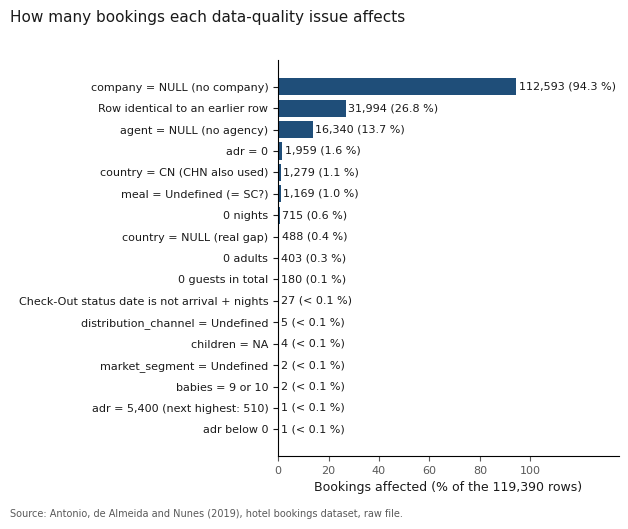

In [22]:
# ── Chart: bookings affected by each issue that needs a cleaning rule ────────

chart_data = issues_summary[issues_summary['needs_rule'] == 'Yes'].sort_values('rows')

fig, ax = plt.subplots(figsize=(6.3, 5.2))
ax.barh(chart_data['issue'], chart_data['% of rows'], color='#1F4E79')

# Exact value at the end of each bar: number of bookings and percentage
# (values below 0.1 % are written as "< 0.1 %" instead of a misleading "0.0 %")
for position, (rows, percent) in enumerate(zip(chart_data['rows'], chart_data['% of rows'])):
    percent_text = f'{percent:.1f} %' if percent >= 0.1 else '< 0.1 %'
    ax.text(percent + 1, position, f'{rows:,} ({percent_text})', va='center', fontsize=8, color='#1A1A1A')

ax.set_xlim(0, 135)
ax.set_xticks(range(0, 101, 20))   # a percentage cannot pass 100; the extra space is for the labels
ax.set_xlabel('Bookings affected (% of the 119,390 rows)', fontsize=9, color='#1A1A1A')
fig.suptitle('How many bookings each data-quality issue affects', x=0.01, ha='left', fontsize=11, color='#1A1A1A')
ax.tick_params(axis='y', labelsize=8, colors='#1A1A1A')
ax.tick_params(axis='x', labelsize=8, colors='#595959')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
fig.text(0.01, 0.005, 'Source: Antonio, de Almeida and Nunes (2019), hotel bookings dataset, raw file.',
         fontsize=7, color='#595959')
fig.tight_layout(rect=(0, 0.02, 1, 0.97))

fig.savefig(IMAGES_DIR / 'quality_issues.png', dpi=200)
plt.show()

## 6. Export

In [23]:
# ── Export ────────────────────────────────────────────────────────────────────
issues_summary.to_csv(OUTPUT_DIR / 'quality_issues_summary.csv', index=False)
placeholder_counts.to_csv(OUTPUT_DIR / 'placeholders_per_field.csv')
duplicates_by.to_csv(OUTPUT_DIR / 'duplicates_by_group.csv')
group_size_counts.rename_axis('copies in the group').rename('number of groups').to_csv(OUTPUT_DIR / 'duplicate_group_sizes.csv')
date_checks.to_csv(OUTPUT_DIR / 'date_checks.csv')
status_by_canceled.to_csv(OUTPUT_DIR / 'status_by_is_canceled.csv')
meal_by_hotel.to_csv(OUTPUT_DIR / 'meal_by_hotel.csv')

sorted(p.name for p in OUTPUT_DIR.iterdir())

['date_checks.csv',
 'duplicate_group_sizes.csv',
 'duplicates_by_group.csv',
 'meal_by_hotel.csv',
 'placeholders_per_field.csv',
 'quality_issues_summary.csv',
 'status_by_is_canceled.csv']

## Conclusions

### Main findings
1. **Placeholders:** `NULL` in `company` (94.3 %) and `agent` (13.7 %) means "not applicable", not missing. Real gaps are few: 488 `country` and 4 `children`. `meal = Undefined` is used only by the Resort Hotel and probably means the same as `SC`.
2. **Duplicates:** 31,994 rows (26.8 %) repeat an earlier row in all 32 fields. Without a booking ID it is impossible to tell copies from identical bookings; they cluster in non-refundable and cancelled bookings of the City Hotel.
3. **Odd values:** one negative `adr`, one `adr` of 5,400, 1,959 bookings with `adr` = 0, 180 bookings with no guests, 715 with 0 nights, and a few extreme party sizes.
4. **Dates:** all arrival dates are valid; the week number uses a Sunday-based rule, not ISO weeks; the status date is coherent with the status (27 check-outs differ).
5. **Redundancy:** `reservation_status` contains `is_canceled`, so it must never be used to explain cancellations.

### Limitations
- Whether duplicates are errors cannot be proved with this file.
- `CN` is probably China, but the source does not confirm it.

### Suggested next steps
- Task 1.6: the students choose a rule for each issue marked "Yes" in `quality_issues_summary.csv`.